In [143]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from models import TCVAE
from train_utils import *
from losses import *

In [144]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [145]:
fname =  'P-15'
savedir = 'msl_kl12'

In [146]:
time_series = np.load(f"../datasets/MSL_SMAP/train/{fname}.npy")
window_size = 200
step_size = 1
windows, dmin, dmax = create_windows_min_max_2(time_series, window_size, step_size)
print(windows.shape)

(3483, 200, 55)


In [147]:
# Define the input_size, feature_size, hidden_size, and latent_size
seq_len = windows.shape[1]
input_dim = windows.shape[2]
hid_size = 200
latent_dim = 100
batch_size = 50

# Load the saved model
loaded_model = TCVAE(input_dim=input_dim, seq_len=seq_len, latent_dim=latent_dim, hidden_dim=hid_size, batch_size=batch_size)
loaded_model.load_state_dict(torch.load(f"gen_models/{savedir}/gen_anom_{fname}.pth")['model_state_dict'])

# Use the loaded model
loaded_model.eval()

TCVAE(
  (dropout): Dropout(p=0.1, inplace=False)
  (encoder): Sequential(
    (0): Conv1d(55, 200, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): Conv1d(200, 400, kernel_size=(3,), stride=(1,), padding=(1,))
    (3): ReLU()
    (4): Conv1d(400, 800, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): ReLU()
  )
  (fc_mu): Linear(in_features=160000, out_features=100, bias=True)
  (fc_logvar): Linear(in_features=160000, out_features=100, bias=True)
  (fc_decoder): Linear(in_features=100, out_features=160000, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose1d(800, 400, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): ConvTranspose1d(400, 200, kernel_size=(3,), stride=(1,), padding=(1,))
    (3): ReLU()
    (4): ConvTranspose1d(200, 55, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): ReLU()
  )
)

In [148]:
def inject_anomaly_all2(model, x, scale):
    batch_size = x.shape[0]
    
    with torch.no_grad():
        model = model.to(device)
        x = torch.tensor(x, dtype=torch.float32).to(device)
        # Reshape the input to (batch_size, input_dim, seq_len) for Conv1d
        x = x.permute(0, 2, 1)  # Changes (batch_size, seq_len, input_dim) to (batch_size, input_dim, seq_len)

        # Encoding
        x = model.encoder(x)  # Shape: (batch_size, hidden_dim*4, conv_output_size)
        x = x.view(batch_size, -1)  # Flatten for fully connected layers
        
        # Latent space
        mu = model.fc_mu(x)
        logvar = model.fc_logvar(x)
        z = model.reparameterize(mu, logvar)
        z = model.dropout(z)
        
        # Decoding
        x = model.fc_decoder(z)
        x = x.view(batch_size, model.hidden_dim * 4, -1)  # Reshape back for transposed conv layers
        x_recon = model.decoder(x)  # Reconstructed output
        
        # Reshape back to (batch_size, seq_len, input_dim)
        x_recon = x_recon.permute(0, 2, 1)  # Changes back to (batch_size, seq_len, input_dim)
        
        
        # ==== Perturbation =====
        z_pert = model.reparameterize_pert(mu, logvar, model.perturb_scale*scale)
        
        # Decoding
        x_pert = model.fc_decoder(z_pert)
        x_pert = x_pert.view(batch_size, model.hidden_dim * 4, -1)  # Reshape back for transposed conv layers
        x_anom = model.decoder(x_pert)  # Reconstructed output
        
        # Reshape back to (batch_size, seq_len, input_dim)
        x_anom = x_anom.permute(0, 2, 1)  # Changes back to 
    
    return x_anom, x_recon, z, z_pert


In [150]:
windows_sampled = windows.copy()
generated_abnormal_windows, reconstructed_windows, z_s, z_abnormal_s = inject_anomaly_all2(loaded_model, windows_sampled, 1.0)

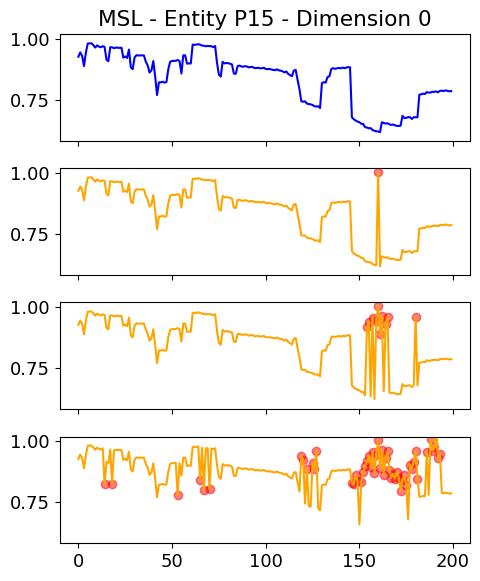

In [158]:
indices = 500
dim = 0

org_window = pd.DataFrame(np.squeeze(windows_sampled[indices]))
rec_window = pd.DataFrame(np.squeeze(reconstructed_windows.cpu()[indices]))
abn_window = pd.DataFrame(np.squeeze(generated_abnormal_windows.cpu()[indices]))


def abn_by_threshold(org_ts, abn_ts, threshold):
    # Calculate absolute difference
    diff = np.abs(org_ts - abn_ts)**2

    # Identify points that deviate beyond the threshold
    deviations = diff > threshold
    deviation_indices = np.where(deviations)[0]
    diff[~deviations] = 0
    abn_ts[~deviations] = org_ts[~deviations]

    return abn_ts, deviation_indices

org_ts = org_window[dim].copy()
amp = max(org_ts) - min(org_ts)

thresholds = [0.4, 0.2, 0.05]

# Plotting
plt.rcParams.update({'font.size': 13})
fig, ax = plt.subplots(len(thresholds) + 1, 1, figsize=(5, (len(thresholds) + 1) * 1.5))
ymin = min(org_ts) - 0.1 * amp
ymax = max(org_ts) + 0.1 * amp

# Plot original window
ax[0].plot(org_ts, 'blue')
ax[0].set_ylim(ymin, ymax)
ax[0].set_title('MSL - Entity P15 - Dimension 0')
ax[0].set_xticklabels([])

for i, threshold in enumerate(thresholds):
    abn_ts_input = abn_window[dim].copy()
    abn_ts, deviation_indices = abn_by_threshold(org_ts, abn_ts_input, threshold * amp)
    ax[i + 1].plot(abn_ts, 'orange')
    ax[i + 1].scatter(deviation_indices, abn_ts[deviation_indices], color="red", alpha=0.5)
    ax[i + 1].set_ylim(ymin, ymax)
    if i+1 < len(thresholds):
        ax[i+1].set_xticklabels([])

plt.tight_layout()
plt.savefig('msl-p15-d0.pdf', dpi=300, bbox_inches='tight')
plt.show()
